# Aufgabe 1.1

Gegeben:
$$\phi_1(t) = 1 - t, \quad \phi_2(t) = t, \quad \langle u, v \rangle = \int_0^1 u'(t) v'(t) \, \mathrm{d}t$$

Orthogonale Basisfunktionen mit $\phi_k(0) = \phi_k(1) = 0$:
$$\phi_3(t) = \phi_1(t) \phi_2(t) = t(1 - t)$$
$$\phi_4(t) = (\phi_1(t) - \phi_2(t)) \phi_3(t) = t(1 - t)(1 - 2t)$$


⎡1   -1   0    0 ⎤
⎢                ⎥
⎢-1  1    0    0 ⎥
⎢                ⎥
⎢0   0   1/3   0 ⎥
⎢                ⎥
⎣0   0    0   1/5⎦


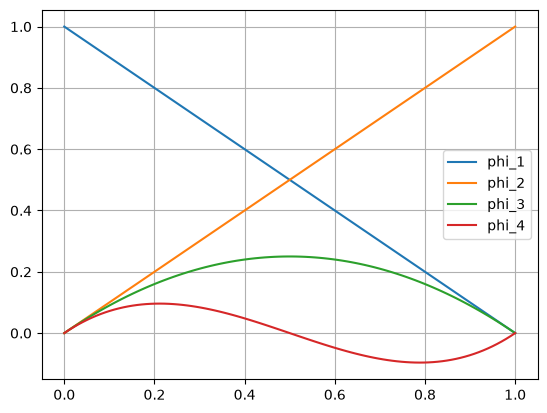

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

t = sp.symbols('t')
dot = lambda u, v: sp.integrate(sp.diff(u, t) * sp.diff(v, t), (t, 0, 1))

phi1 = 1 - t
phi2 = t
phi3 = phi1 * phi2
phi4 = (phi1 - phi2) * phi3
basis = [phi1, phi2, phi3, phi4]

# Steifigkeitsmatrix K_ij = <phi_i, phi_j>
K = sp.Matrix([[dot(fi, fj) for fj in basis] for fi in basis])
sp.pprint(K)

# Plot
xp = np.linspace(0, 1, 100)
for i, phi in enumerate(basis, 1):
    plt.plot(xp, sp.lambdify(t, phi)(xp), label=f"phi_{i}")
plt.legend()
plt.grid()
plt.show()


# Aufgabe 2: Konvergenzrate

Starke Form:
$$-\Delta u = 2\pi^2 \sin(\pi x)\sin(\pi y) \quad \text{in } \Omega = [0,1]^2, \quad u|_{\partial\Omega} = 0$$

Schwache Form:
$$\int_\Omega \nabla u \cdot \nabla v \, \mathrm{d}x = \int_\Omega 2\pi^2 \sin(\pi x)\sin(\pi y) \, v \, \mathrm{d}x \quad \forall v \in H_0^1(\Omega)$$


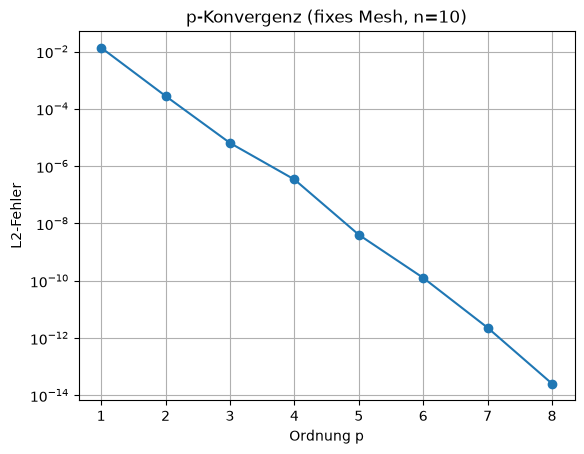

In [2]:
# 2.1: Fixes Mesh (n=10), variable Ordnung (p-Konvergenz)
from ngsolve import *
from ngsolve.meshes import MakeStructured2DMesh
import numpy as np
import matplotlib.pyplot as plt

mesh = MakeStructured2DMesh(quads=False, nx=10, ny=10, mapping=lambda x, y: (x, y))
ua = sin(pi*x)*sin(pi*y)
orders = np.arange(1, 9)
errs_p = []

for p in orders:
    V = H1(mesh, order=int(p), dirichlet='bottom|right|top|left')
    u, v = V.TnT()
    a = BilinearForm(V)
    a += grad(u)*grad(v)*dx
    f = LinearForm(V)
    f += 2*pi**2*ua*v*dx
    a.Assemble()
    f.Assemble()
    
    gfu = GridFunction(V)
    gfu.vec.data = a.mat.Inverse(freedofs=V.FreeDofs()) * f.vec
    errs_p.append(Integrate((gfu - ua)**2, mesh)**0.5)

plt.semilogy(orders, errs_p, 'o-')
plt.xlabel('Ordnung p')
plt.ylabel('L2-Fehler')
plt.title('p-Konvergenz (fixes Mesh, n=10)')
plt.grid()
plt.show()


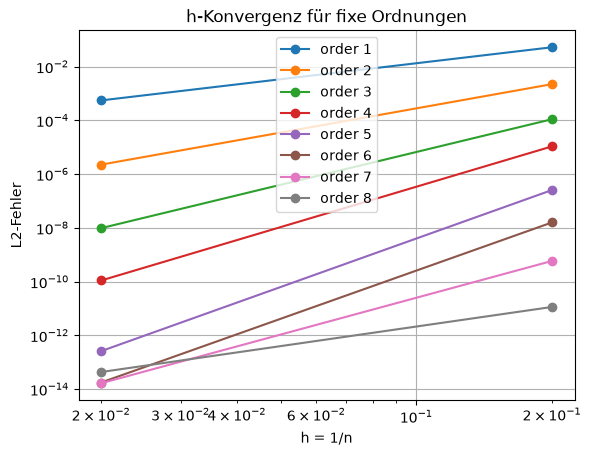

In [3]:
# 2.2: Variables Mesh (n=5, 50), fixe Ordnungen (h-Konvergenz)
ns = np.array([5, 50])
errs_h = []

for n in ns:
    mesh = MakeStructured2DMesh(quads=False, nx=n, ny=n, mapping=lambda x, y: (x, y))
    err_n = []
    for p in orders:
        V = H1(mesh, order=int(p), dirichlet='bottom|right|top|left')
        u, v = V.TnT()
        a = BilinearForm(V)
        a += grad(u)*grad(v)*dx
        f = LinearForm(V)
        f += 2*pi**2*ua*v*dx
        with TaskManager():
            a.Assemble()
            f.Assemble()
            gfu = GridFunction(V)
            gfu.vec.data = a.mat.Inverse(freedofs=V.FreeDofs()) * f.vec
            err_n.append(Integrate((gfu - ua)**2, mesh)**0.5)
    errs_h.append(err_n)

errs_h = np.array(errs_h)
for i in range(len(orders)):
    plt.loglog(1/ns, errs_h[:, i], 'o-', label=f'order {i+1}')
plt.xlabel('h = 1/n')
plt.ylabel('L2-Fehler')
plt.title('h-Konvergenz für fixe Ordnungen')
plt.legend()
plt.grid()
plt.show()
